In [2]:
import pandas as pd

In [3]:

data

,record_id,month,year,City,country_id,Country,Latitude,Longitude,AverageTemperatureCelsius,AverageTemperatureUncertaintyCelsius
0,474381,6,1853,Auckland,NEW,New Zealand,36.17S,175.03E,11.059,2.754
1,474382,7,1853,Auckland,NEW,New Zealand,36.17S,175.03E,11.327,1.416
2,474383,8,1853,Auckland,NEW,New Zealand,36.17S,175.03E,11.585,0.861
3,474384,9,1853,Auckland,NEW,New Zealand,36.17S,175.03E,11.432,0.910
4,474385,10,1853,Auckland,NEW,New Zealand,36.17S,175.03E,12.707,1.102
...,...,...,...,...,...,...,...,...,...,...
47063,8258725,4,2013,Wroclaw,POL,Poland,50.63N,16.48E,7.939,0.156
47064,8258726,5,2013,Wroclaw,POL,Poland,50.63N,16.48E,12.808,0.272
47065,8258727,6,2013,Wroclaw,POL,Poland,50.63N,16.48E,16.204,0.185
47066,8258728,7,2013,Wroclaw,POL,Poland,50.63N,16.48E,19.317,0.317


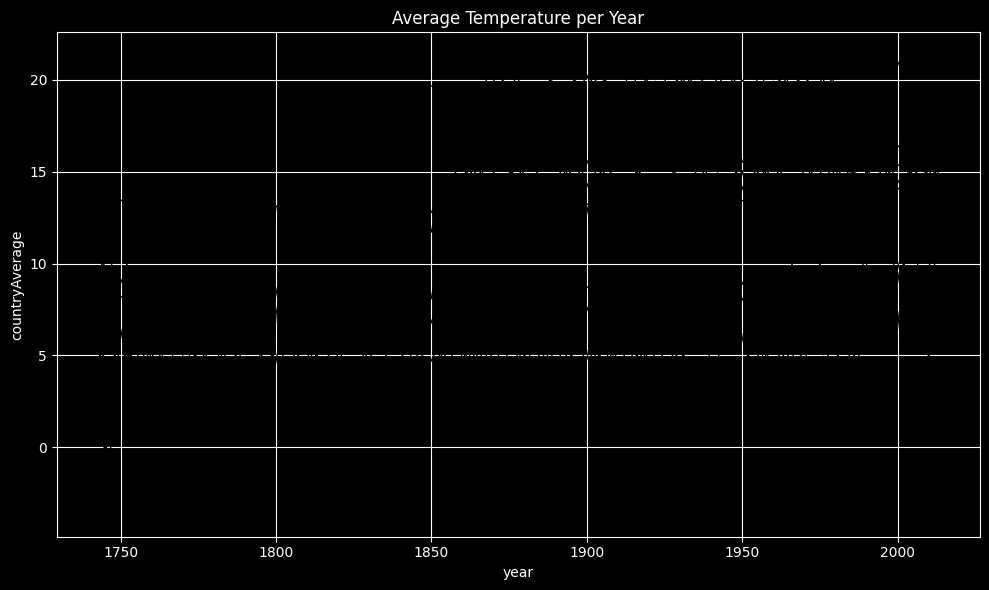

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("temperatures_clean.csv")
avg_df = df.groupby(["year", "Country"], as_index=False)["AverageTemperatureCelsius"].mean()
countries = avg_df["Country"].unique()



In [13]:

for i, country in enumerate(countries):
    ax = axes[i]
    country_df = df[df["Country"] == country].copy()

    # one color per city
    cities = sorted(country_df["City"].dropna().unique())
    cmap = plt.cm.tab20

    for j, city in enumerate(cities):
        city_df = country_df[country_df["City"] == city]
        city_avg = city_df.groupby("year", as_index=False)["AverageTemperatureCelsius"].mean()
        city_avg = city_avg.sort_values("year")

        ax.plot(
            city_avg["year"],
            city_avg["AverageTemperatureCelsius"],
            color=cmap(j % 20),
            linewidth=1,
            label=city
        )

    ax.set_title(country, fontsize=13)
    ax.grid(True, alpha=0.4)




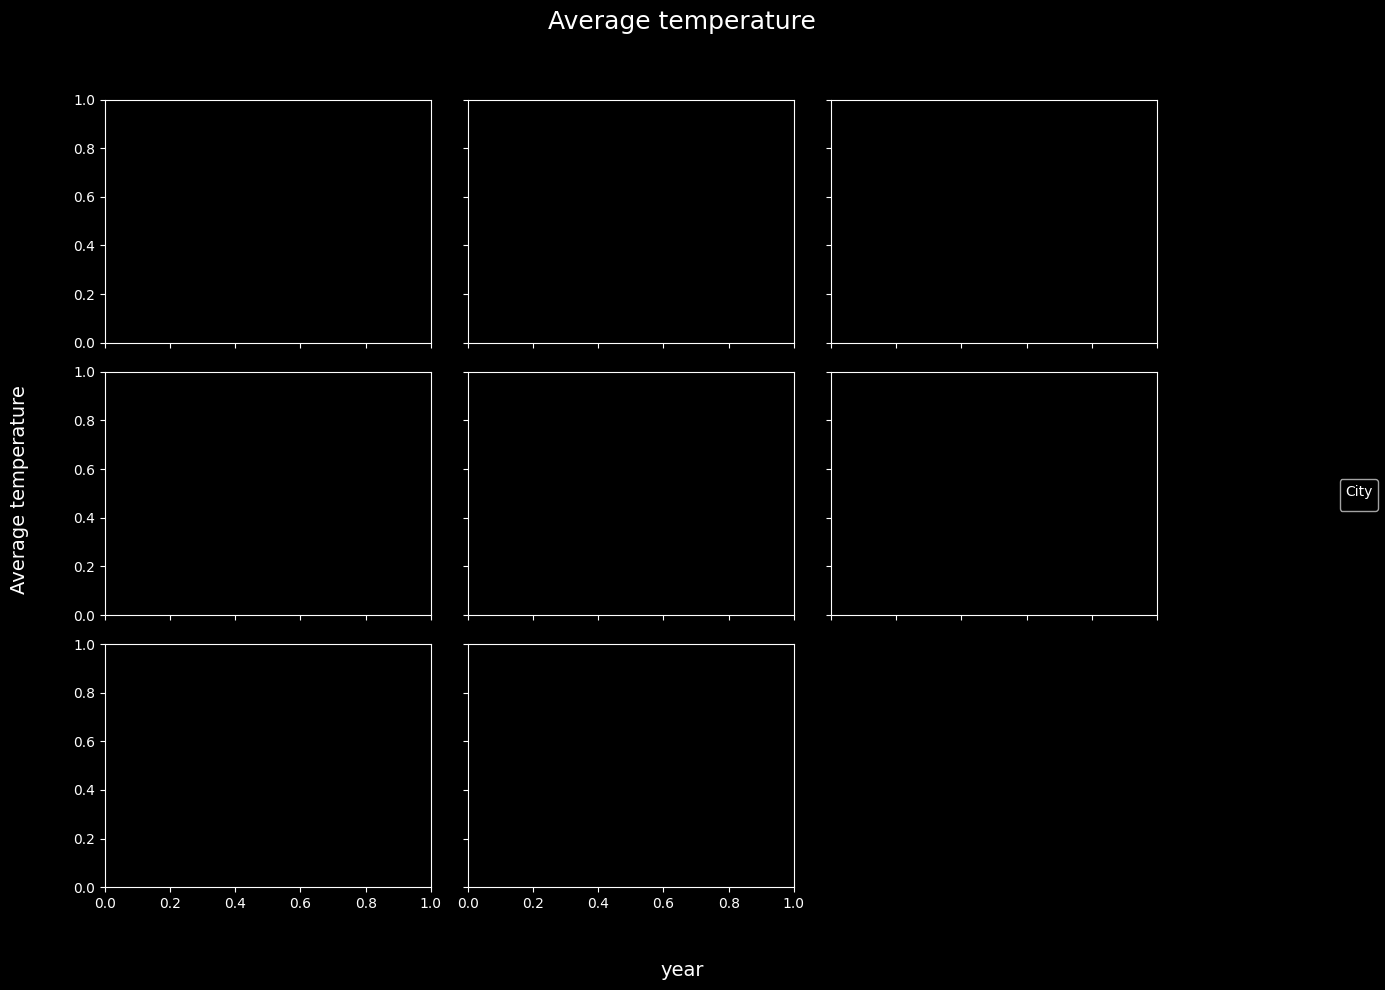

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10), sharex=True, sharey=True)
axes = axes.flatten()

for k in range(len(countries), len(axes)):
    axes[k].axis("off")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="City", loc="center right")

fig.suptitle("Average temperature", fontsize=18)
fig.supxlabel("year", fontsize=14)
fig.supylabel("Average temperature", fontsize=14)

plt.tight_layout(rect=[0.03, 0.03, 0.85, 0.95])
plt.show()
